# Task 8 — Explainable Artificial Intelligence (XAI)
### UniMatch AI — 10-Task Computational Intelligence Pipeline

**Input:** Trained ML / DL models & test data — Task 6 models (`task6_outputs/models/`), Task 7 DNNs (`task7_outputs/`), Task 5 feature matrices.

**Steps:** Feature importance → SHAP analysis → LIME explanation → Counterfactual analysis → Trust score → Fairness assessment → Applicant-facing explanation → Explainability dashboard

**Deliverables:** SHAP Report, LIME Report, Counterfactual Analysis, Explainability Dashboard, Trust Score Report (+ Fairness Report)

> **Which models are explained?** For each dataset, the **best Task 6 model** (by validation ROC-AUC, read from `evaluation_report_<dataset>.csv`) and the **Task 7 DNN**. Every explanation is computed in the **original (unscaled) feature units**, so the numbers are readable; scaling is applied inside the prediction functions.
>
> **Running in Colab:** run Tasks 5 → 6 → 7 → 8 in one session, or keep the output folders in Google Drive (`DRIVE_DIR` below).

## 0. Setup

In [1]:
import importlib, subprocess, sys
for pkg in ['shap', 'lime']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import os, json, shutil, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from lime.lime_tabular import LimeTabularExplainer
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)
# Local run (from the repository's notebooks/ folder): write straight into ../outputs/task8_output and
# ../reports. In Colab, fall back to ./task8_outputs as before.
LOCAL_REPO = os.path.isdir('../outputs')
out_dir = '../outputs/task8_output' if LOCAL_REPO else './task8_outputs'
report_dir = '../reports' if os.path.isdir('../reports') else out_dir
os.makedirs(out_dir, exist_ok=True)
print('shap', shap.__version__)

shap 0.54.1


## 1. Load data, models and rebuild the Task 6 / Task 7 splits

In [2]:
DRIVE_DIR = '/content/drive/MyDrive/UniMatch'
SEARCH_DIRS = ['.', './task5_outputs', './task6_outputs', './task7_outputs', './task6_outputs/models',
               '../outputs/task5_output', '../outputs/task6_output', '../outputs/task6_output/models',
               '../outputs/task7_output', '/content', DRIVE_DIR,
               f'{DRIVE_DIR}/task5_outputs', f'{DRIVE_DIR}/task6_outputs', f'{DRIVE_DIR}/task7_outputs']

def find_file(name):
    for d in SEARCH_DIRS:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    raise FileNotFoundError(f"'{name}' not found in {SEARCH_DIRS}. Run Tasks 5-7 first or put the outputs in DRIVE_DIR.")

uni_df  = pd.read_csv(find_file('feature_matrix_university.csv'))
grad_df = pd.read_csv(find_file('feature_matrix_graduate.csv'))
for df, name, t in [(uni_df, 'university', 'admit'), (grad_df, 'graduate', 'chance_of_admit')]:
    if df[t].isna().any():
        raise ValueError(f'{name} feature matrix has rows without a target - the file looks truncated.')

feat_cols = json.load(open(find_file('feature_columns.json')))
dnn_cfg = json.load(open(find_file('dnn_config.json')))
THRESHOLD = feat_cols.get('graduate_threshold', 0.7)
NEEDS_SCALING = {'Logistic Regression', 'SVM'}          # as in Task 6

D = {}
for name, df, target in [('university', uni_df, 'admit'), ('graduate', grad_df, 'chance_of_admit')]:
    feats = feat_cols[name]
    X = df[feats].astype(float)
    y = df[target].astype(int) if name == 'university' else (df[target] >= THRESHOLD).astype(int)
    tr, te = (df['split'] == 'train').values, (df['split'] == 'test').values   # Task 5 split, as in Tasks 6-7
    X_tr, X_te, y_tr, y_te = X[tr], X[te], y[tr], y[te]

    # Task 6's best model = highest validation ROC-AUC
    best_ml = pd.read_csv(find_file(f'evaluation_report_{name}.csv')).sort_values('val_roc_auc', ascending=False).iloc[0]['model']
    ml_model = joblib.load(find_file(f"{name}/{best_ml.lower().replace(' ', '_')}.pkl"))
    ml_scaler = joblib.load(find_file(f'{name}/scaler.pkl'))
    dnn = keras.models.load_model(find_file(f'dnn_{name}.keras'))
    dnn_scaler = joblib.load(find_file(f'dnn_scaler_{name}.pkl'))
    assert dnn_cfg[name]['features'] == feats, 'Task 6 and Task 7 must use the same feature list'

    D[name] = dict(feats=feats, X_tr=X_tr, X_te=X_te, y_tr=y_tr.values, y_te=y_te.values, df_te=df.loc[X_te.index],
                   ml_name=best_ml, ml=ml_model, ml_scaler=ml_scaler, dnn=dnn, dnn_scaler=dnn_scaler)
    print(f'{name:10s} best ML model = {best_ml:20s} features = {len(feats)}  test rows = {len(y_te)}')

university best ML model = SVM                  features = 105  test rows = 10741
graduate   best ML model = Logistic Regression  features = 5  test rows = 100


### Prediction functions (input = unscaled features, output = P(admit))

In [3]:
def make_predict_fns(d):
    def ml_proba(X):
        X = np.asarray(X, dtype=float)
        X = pd.DataFrame(X, columns=d['feats'])
        if d['ml_name'] in NEEDS_SCALING:
            X = pd.DataFrame(d['ml_scaler'].transform(X), columns=d['feats'])
        return d['ml'].predict_proba(X)[:, 1]
    def dnn_proba(X):
        X = d['dnn_scaler'].transform(pd.DataFrame(np.asarray(X, dtype=float), columns=d['feats']))
        return d['dnn'].predict(X.astype('float32'), verbose=0, batch_size=4096).ravel()
    return ml_proba, dnn_proba

for name, d in D.items():
    d['ml_proba'], d['dnn_proba'] = make_predict_fns(d)
    d['p_ml'], d['p_dnn'] = d['ml_proba'](d['X_te']), d['dnn_proba'](d['X_te'])
    print(f"{name:10s} test ROC-AUC  {d['ml_name']}: {roc_auc_score(d['y_te'], d['p_ml']):.4f}   "
          f"DNN: {roc_auc_score(d['y_te'], d['p_dnn']):.4f}   (should match Tasks 6 and 7)")

university test ROC-AUC  SVM: 0.7602   DNN: 0.7795   (should match Tasks 6 and 7)
graduate   test ROC-AUC  Logistic Regression: 0.9558   DNN: 0.9463   (should match Tasks 6 and 7)


## 2. Feature importance (permutation importance)

Model-agnostic: how much the test ROC-AUC drops when one feature is randomly shuffled (on up to 1,000 university / all graduate test rows). Computed the same way for the ML model and the DNN, so they can be compared directly.

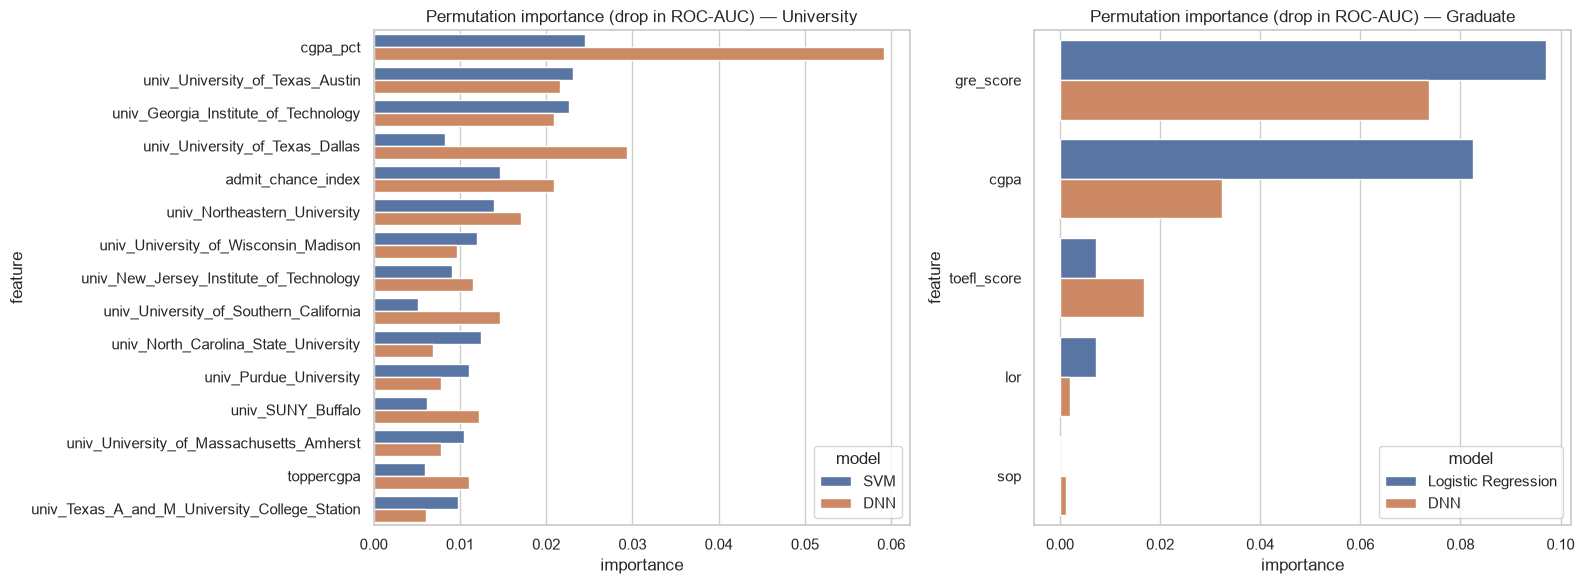

In [4]:
class ProbaWrapper:   # lets sklearn's permutation_importance call any predict function
    def __init__(self, f): self.f = f
    def fit(self, X, y): return self
    def predict_proba(self, X): p = self.f(X); return np.c_[1 - p, p]

def auc_scorer(est, X, y): return roc_auc_score(y, est.predict_proba(X)[:, 1])

PERM_ROWS = {'university': 1000, 'graduate': 3000}
fi_rows = []
for name, d in D.items():
    # The university SVM predicts ~700 rows/s (23k support vectors), so its sample is kept small.
    n = min(PERM_ROWS[name], len(d['y_te']))
    idx = np.random.RandomState(RANDOM_STATE).choice(len(d['y_te']), n, replace=False)
    Xs, ys = d['X_te'].iloc[idx], d['y_te'][idx]
    for label, f in [(d['ml_name'], d['ml_proba']), ('DNN', d['dnn_proba'])]:
        r = permutation_importance(ProbaWrapper(f), Xs, ys, scoring=auc_scorer, n_repeats=5, random_state=RANDOM_STATE)
        fi_rows += [{'dataset': name, 'model': label, 'feature': c, 'importance': m, 'std': s}
                    for c, m, s in zip(d['feats'], r.importances_mean, r.importances_std)]
feature_importance = pd.DataFrame(fi_rows)
feature_importance.to_csv(f'{out_dir}/feature_importance_permutation.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, name in zip(axes, D):
    t = feature_importance[feature_importance['dataset'] == name]
    order = t.groupby('feature')['importance'].mean().sort_values(ascending=False).index[:15]   # top 15 shown
    sns.barplot(data=t[t['feature'].isin(order)], y='feature', x='importance', hue='model', order=order, ax=ax)
    ax.set_title(f'Permutation importance (drop in ROC-AUC) — {name.title()}')
plt.tight_layout(); plt.savefig(f'{out_dir}/feature_importance_permutation.png', dpi=150); plt.show()

## 3. SHAP analysis

SHAP splits each prediction into a contribution per feature (in probability units, relative to the average prediction). A model-agnostic explainer is used for both models, with 100 training rows as background, on a sample of test applicants.

In [5]:
# Sample sizes keep the model-agnostic explainer affordable for slow models (the university SVM
# predicts ~700 rows/s): cost = applicants x evaluations x background rows.
N_SHAP = {'university': 60, 'graduate': 100}
N_BG = {'university': 25, 'graduate': 100}
# University (105 features): the minimum the permutation explainer accepts. Graduate (few features):
# 'auto' lets SHAP use its exact explainer, which needs 2^n_features evaluations.
MAX_EVALS = {name: 2 * len(d['feats']) + 1 if len(d['feats']) > 10 else 'auto' for name, d in D.items()}
shap_values = {}
for name, d in D.items():
    bg = shap.sample(d['X_tr'], N_BG[name], random_state=RANDOM_STATE)
    sample = d['X_te'].sample(min(N_SHAP[name], len(d['X_te'])), random_state=RANDOM_STATE)
    d['shap_sample'] = sample
    for label, f in [('ML', d['ml_proba']), ('DNN', d['dnn_proba'])]:
        explainer = shap.Explainer(f, shap.maskers.Independent(bg), feature_names=d['feats'], seed=RANDOM_STATE)
        shap_values[(name, label)] = explainer(sample, max_evals=MAX_EVALS[name])
        print(f'SHAP done: {name} / {label}')

PermutationExplainer explainer:   8%|▊         | 5/60 [00:00<?, ?it/s]

PermutationExplainer explainer:  12%|█▏        | 7/60 [00:15<01:14,  1.40s/it]

PermutationExplainer explainer:  13%|█▎        | 8/60 [00:18<01:45,  2.03s/it]

PermutationExplainer explainer:  15%|█▌        | 9/60 [00:20<01:56,  2.29s/it]

PermutationExplainer explainer:  17%|█▋        | 10/60 [00:23<02:04,  2.49s/it]

...

PermutationExplainer explainer: 61it [02:43,  2.88s/it]                        

PermutationExplainer explainer: 61it [02:43,  2.93s/it]

SHAP done: university / ML


SHAP done: university / DNN
SHAP done: graduate / ML


SHAP done: graduate / DNN


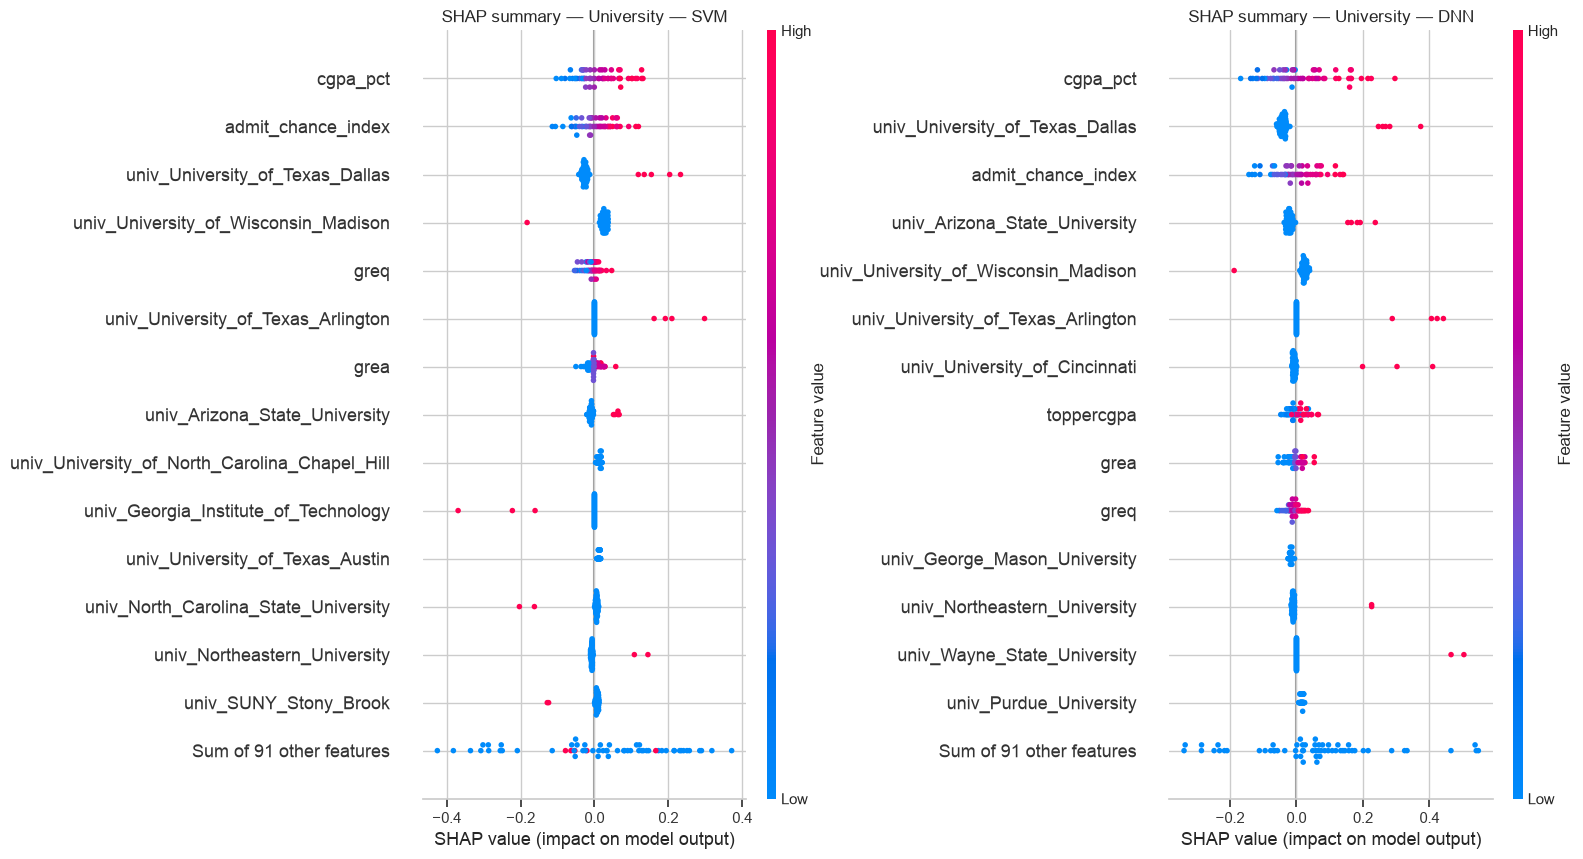

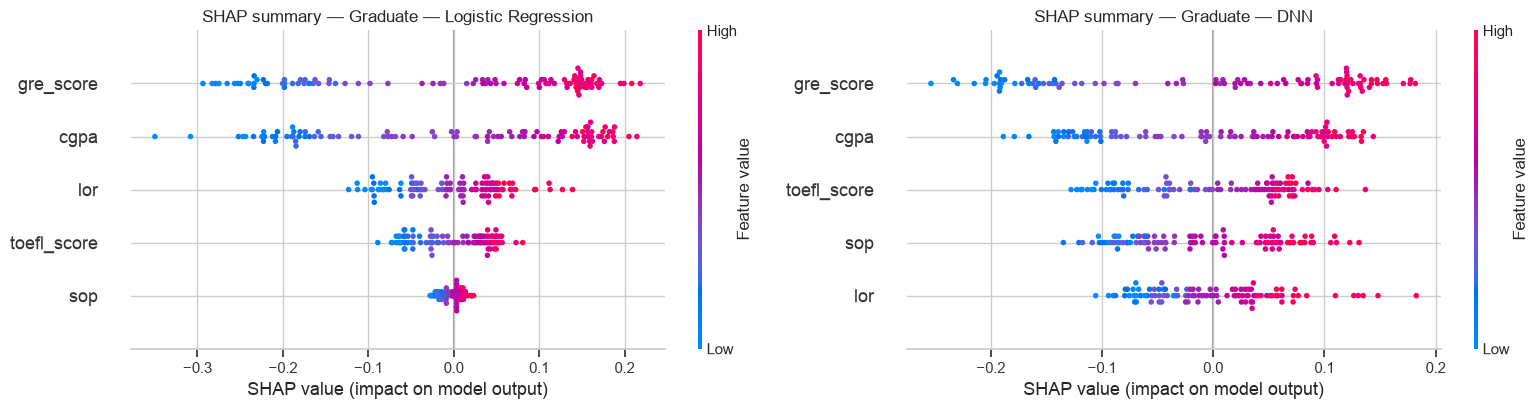

In [6]:
for name, d in D.items():
    fig = plt.figure(figsize=(16, 0.45 * min(15, len(d['feats'])) + 2))
    for i, label in enumerate(['ML', 'DNN']):
        ax = fig.add_subplot(1, 2, i + 1)
        plt.sca(ax)
        shap.plots.beeswarm(shap_values[(name, label)], max_display=15, show=False, plot_size=None)
        ax.set_title(f"SHAP summary — {name.title()} — {d['ml_name'] if label == 'ML' else 'DNN'}")
    plt.tight_layout(); plt.savefig(f'{out_dir}/shap_summary_{name}.png', dpi=150, bbox_inches='tight'); plt.show()

In [7]:
shap_rows = []
for (name, label), sv in shap_values.items():
    mean_abs = np.abs(sv.values).mean(axis=0)
    shap_rows += [{'dataset': name, 'model': D[name]['ml_name'] if label == 'ML' else 'DNN', 'feature': f,
                   'mean_abs_shap': v} for f, v in zip(D[name]['feats'], mean_abs)]
shap_report = pd.DataFrame(shap_rows).sort_values(['dataset', 'model', 'mean_abs_shap'], ascending=[True, True, False])
shap_report.to_csv(f'{out_dir}/shap_report.csv', index=False)

# Do the ML model and the DNN rely on the same features?
for name in D:
    t = shap_report[shap_report['dataset'] == name]
    top = {m: list(g['feature'].head(5)) for m, g in t.groupby('model')}
    print(f'{name}: top-5 features by mean |SHAP|')
    for m, f in top.items(): print(f'   {m:20s} {f}')
    a, b = list(top.values())
    k = min(5, len(a))
    print(f'   overlap of top-{k}: {len(set(a[:k]) & set(b[:k]))}/{k}\n')

university: top-5 features by mean |SHAP|
   DNN                  ['cgpa_pct', 'univ_University_of_Texas_Dallas', 'admit_chance_index', 'univ_Arizona_State_University', 'univ_University_of_Wisconsin_Madison']
   SVM                  ['cgpa_pct', 'admit_chance_index', 'univ_University_of_Texas_Dallas', 'univ_University_of_Wisconsin_Madison', 'greq']
   overlap of top-5: 4/5

graduate: top-5 features by mean |SHAP|
   DNN                  ['gre_score', 'cgpa', 'toefl_score', 'sop', 'lor']
   Logistic Regression  ['gre_score', 'cgpa', 'lor', 'toefl_score', 'sop']
   overlap of top-5: 5/5



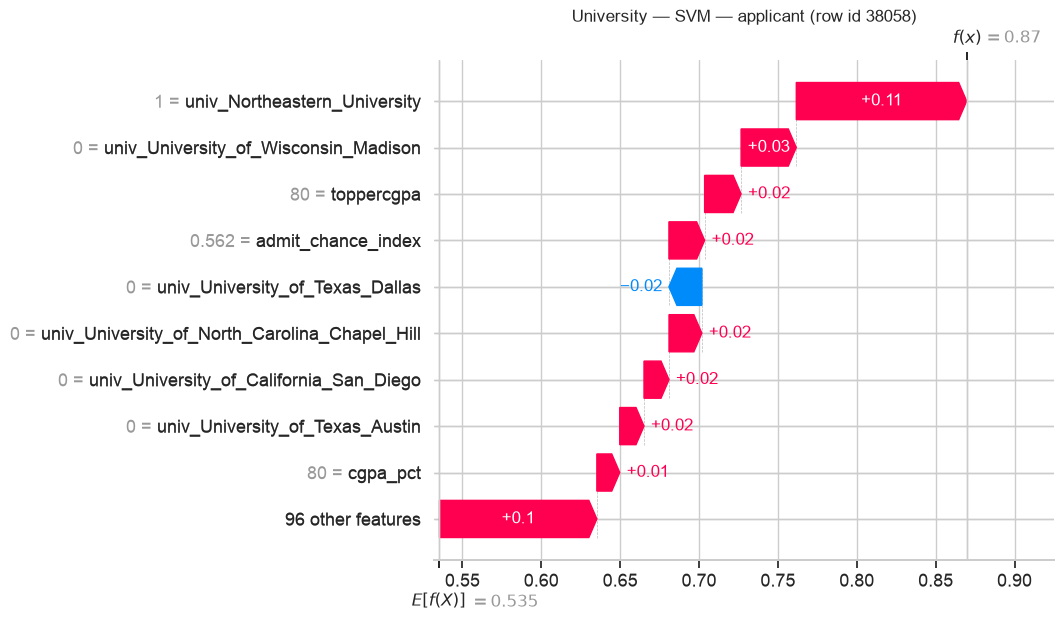

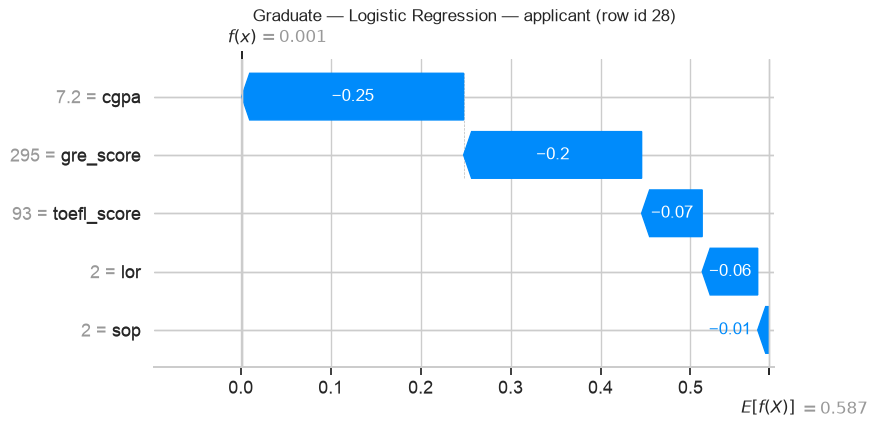

In [8]:
# Local explanation for one applicant (waterfall plot) per dataset
for name, d in D.items():
    sv = shap_values[(name, 'ML')]
    i = int(np.argsort(np.abs(sv.values.sum(axis=1)))[-1])      # applicant with the strongest deviation from average
    plt.figure()
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f"{name.title()} — {d['ml_name']} — applicant (row id {d['shap_sample'].index[i]})")
    plt.savefig(f'{out_dir}/shap_waterfall_{name}.png', dpi=150, bbox_inches='tight'); plt.show()

## 4. LIME explanation

LIME fits a small linear model around one applicant to explain that single prediction. Three applicants per dataset are explained: one confident admit, one borderline case, and one confident reject. The HTML files can be opened in a browser.

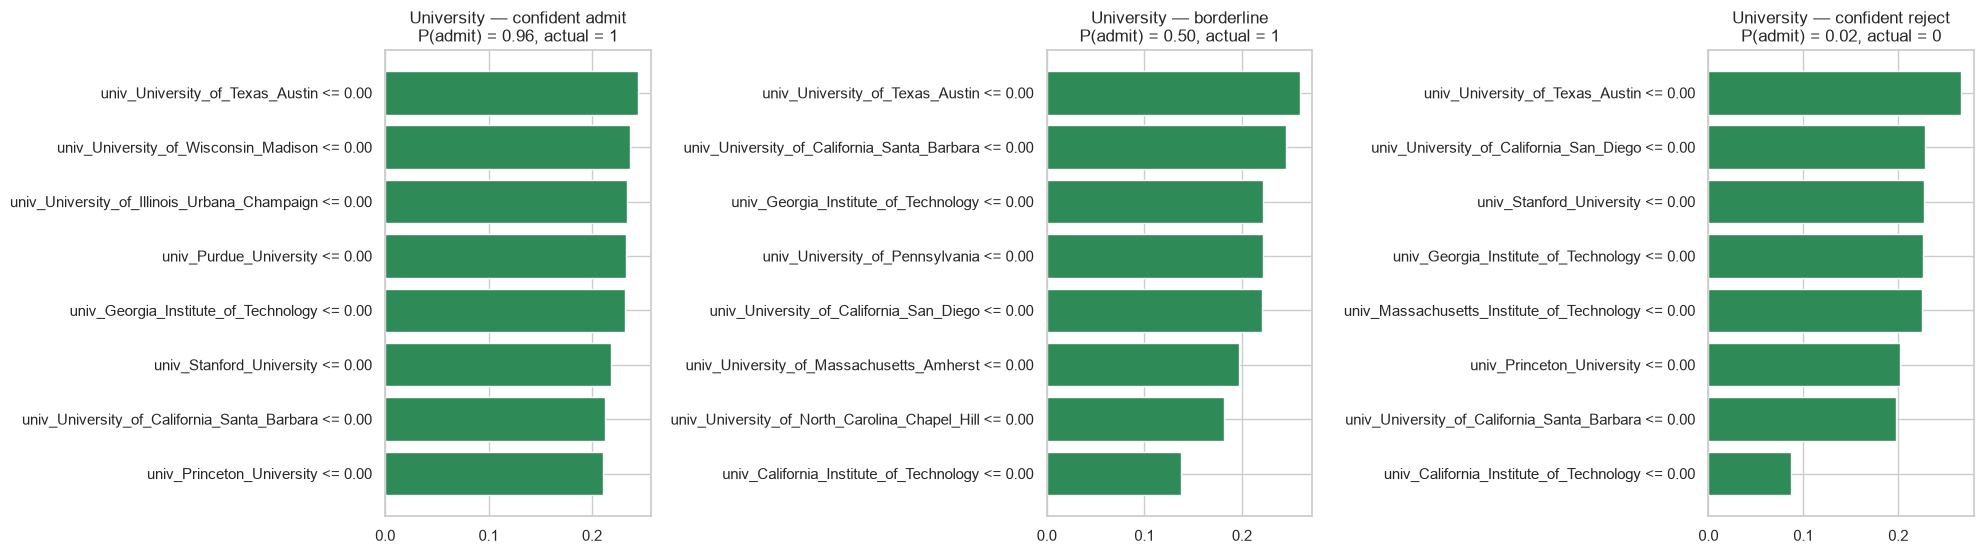

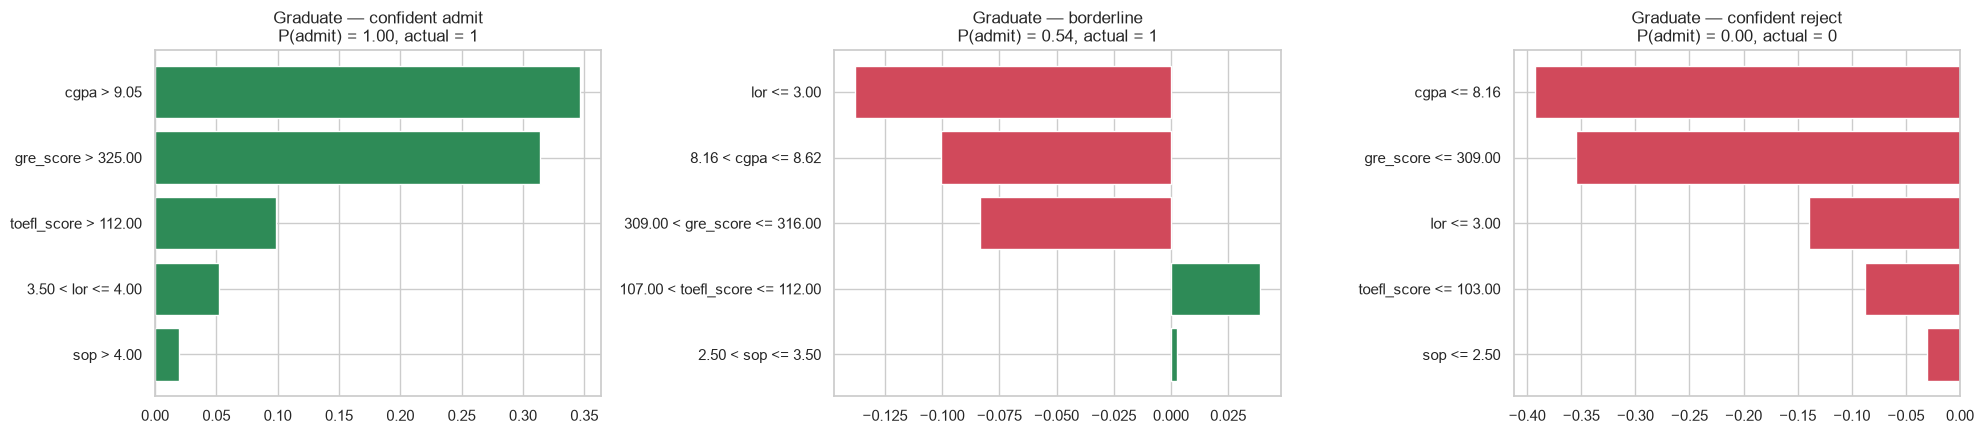

,dataset,case,test_row,p_admit,actual,rule,weight
0,university,confident admit,1762,0.961184,1,univ_University_of_Texas_Austin <= 0.00,0.244633
1,university,confident admit,1762,0.961184,1,univ_University_of_Wisconsin_Madison <= 0.00,0.237081
2,university,confident admit,1762,0.961184,1,univ_University_of_Illinois_Urbana_Champaign <...,0.233587
3,university,confident admit,1762,0.961184,1,univ_Purdue_University <= 0.00,0.232458
4,university,confident admit,1762,0.961184,1,univ_Georgia_Institute_of_Technology <= 0.00,0.232194
5,university,confident admit,1762,0.961184,1,univ_Stanford_University <= 0.00,0.218318
6,university,confident admit,1762,0.961184,1,univ_University_of_California_Santa_Barbara <=...,0.213034
7,university,confident admit,1762,0.961184,1,univ_Princeton_University <= 0.00,0.211097
8,university,borderline,460,0.500000,1,univ_University_of_Texas_Austin <= 0.00,0.259280
9,university,borderline,460,0.500000,1,univ_University_of_California_Santa_Barbara <=...,0.245655


In [9]:
def pick_examples(p):
    return {'confident admit': int(np.argmax(p)), 'borderline': int(np.argmin(np.abs(p - 0.5))),
            'confident reject': int(np.argmin(p))}

lime_rows = []
for name, d in D.items():
    lime_exp = LimeTabularExplainer(d['X_tr'].values, feature_names=d['feats'], class_names=['reject', 'admit'],
                                    mode='classification', discretize_continuous=True, random_state=RANDOM_STATE)
    d['lime'] = lime_exp
    two_col = lambda X, f=d['ml_proba']: np.c_[1 - f(X), f(X)]
    examples = pick_examples(d['p_ml'])
    d['examples'] = examples
    fig, axes = plt.subplots(1, 3, figsize=(20, 0.4 * min(8, len(d['feats'])) + 2.5))
    for ax, (case, i) in zip(axes, examples.items()):
        exp = lime_exp.explain_instance(d['X_te'].values[i], two_col, num_features=min(8, len(d['feats'])))
        exp.save_to_file(f'{out_dir}/lime_{name}_{case.replace(" ", "_")}.html')
        weights = exp.as_list()
        ax.barh([w[0] for w in weights][::-1], [w[1] for w in weights][::-1],
                color=['#2E8B57' if w[1] > 0 else '#D1495B' for w in weights][::-1])
        ax.set_title(f'{name.title()} — {case}\nP(admit) = {d["p_ml"][i]:.2f}, actual = {d["y_te"][i]}')
        lime_rows += [{'dataset': name, 'case': case, 'test_row': i, 'p_admit': d['p_ml'][i], 'actual': d['y_te'][i],
                       'rule': r, 'weight': w} for r, w in weights]
    plt.tight_layout(); plt.savefig(f'{out_dir}/lime_{name}.png', dpi=150); plt.show()

lime_report = pd.DataFrame(lime_rows)
lime_report.to_csv(f'{out_dir}/lime_report.csv', index=False)
lime_report.head(10)

## 5. Counterfactual analysis — "what would need to change?"

For applicants the model predicts as **not admitted**, a greedy search finds a small, realistic set of improvements that flips the prediction to admit. Each step has a cost (e.g. +2 GRE points, +0.1 CGPA); if the total effort would exceed `MAX_COST`, the case is reported as "no realistic change found".

This is done on the **Graduate Admission** dataset, whose inputs are things an applicant can actually change (GRE, TOEFL, CGPA, SOP, LOR, research). The graduate models use these raw attributes directly, so a changed input goes straight into the model. (The University dataset's features include the target university and fit to its admitted cohort, which are not improvements an applicant can make.)

In [10]:
g = D['graduate']
RAW = ['gre_score', 'toefl_score', 'cgpa', 'sop', 'lor', 'research']   # attributes an applicant can change
COLS = list(dict.fromkeys(g['feats'] + RAW))                            # + fixed model inputs (e.g. university_rating)

def to_features(raw):
    """The graduate models use the raw applicant attributes directly, so the feature vector is just
    the (changed) raw values in the model's column order."""
    return np.array([[raw[f] for f in g['feats']]], dtype=float)

# sanity check: rebuilt features match the Task 5 feature matrix
chk = grad_df.head(20)
assert np.allclose(np.vstack([to_features(r[COLS].to_dict()) for _, r in chk.iterrows()]), chk[g['feats']].values, atol=1e-6)

STEPS = {'gre_score': (2, 340, 2 / 50), 'toefl_score': (1, 120, 1 / 28), 'cgpa': (0.1, 10, 0.1 / 3.1),
         'sop': (0.5, 5, 0.5 / 4), 'lor': (0.5, 5, 0.5 / 4), 'research': (1, 1, 0.25)}   # step, max, cost per step
STEPS = {c: s for c, s in STEPS.items() if c in g['feats']}   # changing an attribute the model does not use cannot help

MAX_COST = 1.0   # total effort budget (sum of step costs); above this the change is not considered realistic

def counterfactual(raw, f, max_steps=40):
    raw, changes, p, spent = dict(raw), {}, f(to_features(raw))[0], 0.0
    for _ in range(max_steps):
        if p >= 0.5:
            return raw, changes, p
        best = None
        for c, (step, mx, cost) in STEPS.items():
            if raw[c] + step > mx + 1e-9:
                continue
            trial = dict(raw); trial[c] = round(raw[c] + step, 2)
            gain = (f(to_features(trial))[0] - p) / cost
            if best is None or gain > best[0]:
                best = (gain, c, trial)
        if best is None or spent + STEPS[best[1]][2] > MAX_COST:
            break
        _, c, raw = best
        spent += STEPS[c][2]
        changes[c] = changes.get(c, 0) + STEPS[c][0]
        p = f(to_features(raw))[0]
    return raw, changes, p if p >= 0.5 else None

cf_rows = []
rejected = np.where(g['p_ml'] < 0.5)[0]
for i in rejected:
    row = g['df_te'].iloc[i]
    raw0 = row[COLS].to_dict()
    new, changes, p_new = counterfactual(raw0, g['ml_proba'])
    cf_rows.append({'test_row': i, 'actual_label': g['y_te'][i], 'p_before': g['p_ml'][i],
                    'p_after_ml': p_new, 'p_after_dnn': g['dnn_proba'](to_features(new))[0] if p_new else None,
                    'changes': ', '.join(f'{k} +{v:g}' for k, v in changes.items()) if p_new else 'no realistic change found',
                    **{f'{c}_before': raw0[c] for c in RAW}, **{f'{c}_after': new[c] for c in RAW}})
counterfactuals = pd.DataFrame(cf_rows)
counterfactuals.to_csv(f'{out_dir}/counterfactual_analysis.csv', index=False)
print(f'{len(rejected)} applicants predicted "not admitted"; realistic change found for: {counterfactuals["p_after_ml"].notna().sum()}')
counterfactuals[['test_row', 'p_before', 'changes', 'p_after_ml', 'p_after_dnn']].head(10).round(3)

41 applicants predicted "not admitted"; realistic change found for: 40


,test_row,p_before,changes,p_after_ml,p_after_dnn
0,1,0.120,cgpa +0.9,0.503,0.393
1,3,0.001,no realistic change found,NaN,NaN
2,4,0.094,cgpa +1.1,0.548,0.536
3,5,0.156,cgpa +0.8,0.524,0.452
4,9,0.024,cgpa +1.7,0.525,0.314
5,10,0.024,cgpa +1.7,0.522,0.219
6,12,0.196,cgpa +0.7,0.538,0.332
7,15,0.238,cgpa +0.6,0.544,0.412
8,18,0.003,"cgpa +2.5, gre_score +4",0.547,0.324
9,21,0.009,cgpa +2.1,0.503,0.208


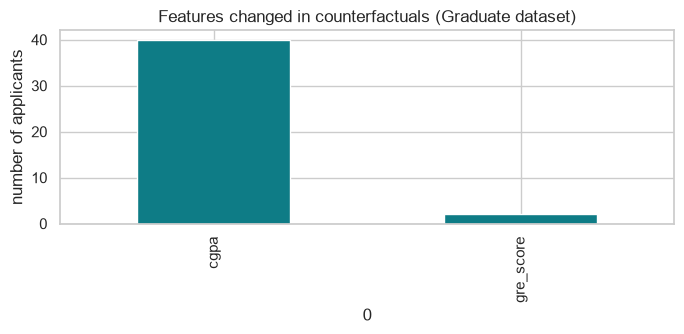

In [11]:
# Which improvement is needed most often?
needed = counterfactuals.loc[counterfactuals['p_after_ml'].notna(), 'changes'].str.extractall(r'(\w+) \+')[0].value_counts()
needed.plot.bar(color='#0E7C86', figsize=(7, 3.5), title='Features changed in counterfactuals (Graduate dataset)')
plt.ylabel('number of applicants'); plt.tight_layout(); plt.savefig(f'{out_dir}/counterfactual_summary.png', dpi=150); plt.show()

## 6. Trust score

For every test applicant, a 0–1 **trust score** combines three checks:

| Component | Meaning |
|---|---|
| **Confidence** | how far the ML probability is from 0.5 (`2·|p − 0.5|`) |
| **Model agreement** | how close the ML and DNN probabilities are (`1 − |p_ML − p_DNN|`) |
| **In-distribution** | how similar the applicant is to the training data (distance to 5 nearest training applicants, turned into a percentile) |

Trust = mean of the three. A useful trust score should show **higher accuracy for higher trust**. (The Graduate test set has only 100 applicants, so its bands contain few people and are noisy — the University results are the more reliable check.)

,dataset,trust_band,applicants,accuracy,mean_trust
0,graduate,Low,5,1.000,0.439
1,graduate,Medium,33,0.818,0.627
2,graduate,High,62,0.919,0.847
3,university,Low,2330,0.603,0.421
4,university,Medium,5294,0.682,0.603
5,university,High,3117,0.785,0.773


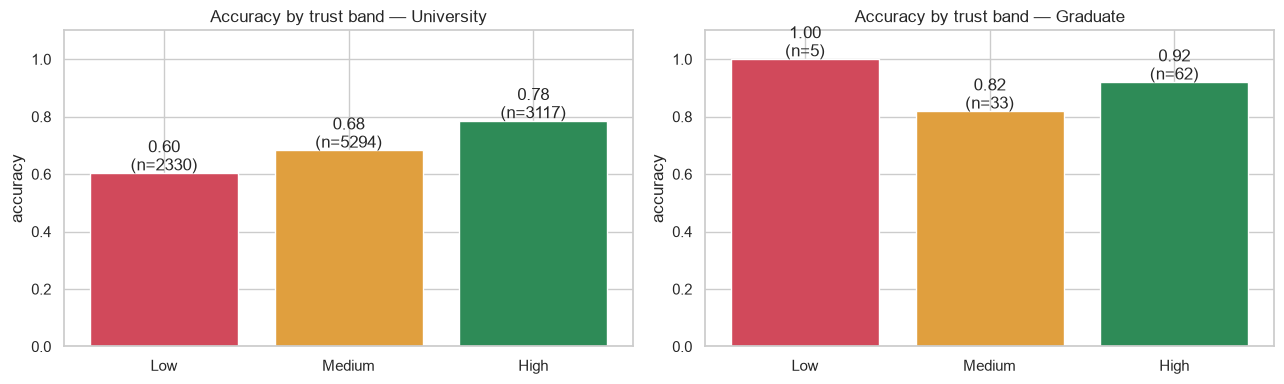

In [12]:
trust_tables = []
for name, d in D.items():
    Ztr = d['dnn_scaler'].transform(d['X_tr']); Zte = d['dnn_scaler'].transform(d['X_te'])
    nn = NearestNeighbors(n_neighbors=6).fit(Ztr)
    ref_rows = Ztr[np.random.RandomState(0).choice(len(Ztr), min(5000, len(Ztr)), replace=False)]
    ref = np.sort(nn.kneighbors(ref_rows)[0][:, 1:].mean(1))     # skip column 0 = the training point itself
    dist = nn.kneighbors(Zte)[0][:, :5].mean(1)
    in_dist = 1 - np.searchsorted(ref, dist) / len(ref)
    t = pd.DataFrame({'dataset': name, 'test_row': np.arange(len(d['y_te'])), 'actual': d['y_te'],
                      'p_ml': d['p_ml'], 'p_dnn': d['p_dnn'],
                      'confidence': 2 * np.abs(d['p_ml'] - 0.5), 'agreement': 1 - np.abs(d['p_ml'] - d['p_dnn']),
                      'in_distribution': in_dist})
    t['trust_score'] = t[['confidence', 'agreement', 'in_distribution']].mean(axis=1)
    t['trust_band'] = pd.cut(t['trust_score'], [0, 0.5, 0.7, 1.0], labels=['Low', 'Medium', 'High'], include_lowest=True)
    t['correct'] = ((t['p_ml'] >= 0.5).astype(int) == t['actual']).astype(int)
    d['trust'] = t
    trust_tables.append(t)
trust = pd.concat(trust_tables, ignore_index=True)
trust.to_csv(f'{out_dir}/trust_scores.csv', index=False)

trust_summary = trust.groupby(['dataset', 'trust_band'], observed=True).agg(
    applicants=('correct', 'size'), accuracy=('correct', 'mean'), mean_trust=('trust_score', 'mean')).reset_index()
trust_summary.to_csv(f'{out_dir}/trust_score_report.csv', index=False)
display(trust_summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, name in zip(axes, D):
    s = trust_summary[trust_summary['dataset'] == name]
    ax.bar(s['trust_band'].astype(str), s['accuracy'], color=['#D1495B', '#E09F3E', '#2E8B57'][:len(s)])
    for x, (a, n) in enumerate(zip(s['accuracy'], s['applicants'])): ax.text(x, a + 0.01, f'{a:.2f}\n(n={n})', ha='center')
    ax.set_ylim(0, 1.1); ax.set_title(f'Accuracy by trust band — {name.title()}'); ax.set_ylabel('accuracy')
plt.tight_layout(); plt.savefig(f'{out_dir}/trust_score_vs_accuracy.png', dpi=150); plt.show()

## 7. Fairness assessment

Neither dataset contains protected attributes (gender, ethnicity, nationality), so this checks whether the model treats **applicant groups that are available** consistently. The full fairness audit with demographic data is in Task 10 (College Admissions dataset).

| Dataset | Groups compared |
|---|---|
| Graduate | research experience (yes / no); undergraduate university rating (1–3 vs 4–5) |
| University | degree programme (MS vs PhD); target university ranked vs unranked |

Metrics per group: selection rate (predicted admit), true-positive rate, false-positive rate. **Demographic-parity difference** = gap in selection rates; **equal-opportunity difference** = gap in TPR. A gap above 0.10 is flagged for discussion — it may reflect real differences in qualifications rather than bias, which is why base rates are shown too.

In [13]:
def group_metrics(y, p, groups):
    rows = []
    yhat = (p >= 0.5).astype(int)
    for gname in pd.unique(groups):
        m = groups == gname
        pos, neg = (y[m] == 1), (y[m] == 0)
        rows.append({'group': gname, 'n': int(m.sum()), 'base_rate': y[m].mean(), 'selection_rate': yhat[m].mean(),
                     'TPR': yhat[m][pos].mean() if pos.any() else np.nan, 'FPR': yhat[m][neg].mean() if neg.any() else np.nan})
    return pd.DataFrame(rows)

gte, ute = D['graduate']['df_te'], D['university']['df_te']
program = np.where(ute.get('program_PhD', 0) == 1, 'PhD', np.where(ute.get('program_MS', 0) == 1, 'MS', 'MS/PhD or both'))
checks = [
    ('graduate', 'research', np.where(gte['research'] == 1, 'research', 'no research')),
    ('graduate', 'university_rating', np.where(gte['university_rating'] >= 4, 'rating 4-5', 'rating 1-3')),
    ('university', 'program', program),
    ('university', 'is_ranked', np.where(ute['is_ranked'] == 1, 'ranked university', 'unranked university')),
]
fair_rows, summary_rows = [], []
for name, attr, groups in checks:
    d = D[name]
    for label, p in [(d['ml_name'], d['p_ml']), ('DNN', d['p_dnn'])]:
        gm = group_metrics(d['y_te'], p, groups).assign(dataset=name, attribute=attr, model=label)
        gm = gm[gm['n'] >= 20]                                   # ignore tiny groups
        fair_rows.append(gm)
        dp = gm['selection_rate'].max() - gm['selection_rate'].min()
        eo = gm['TPR'].max() - gm['TPR'].min()
        summary_rows.append({'dataset': name, 'attribute': attr, 'model': label,
                             'base_rate_gap': gm['base_rate'].max() - gm['base_rate'].min(),
                             'demographic_parity_diff': dp, 'equal_opportunity_diff': eo,
                             'flag': 'review' if max(dp, eo) > 0.10 else 'ok'})
fairness_detail = pd.concat(fair_rows, ignore_index=True)
fairness_summary = pd.DataFrame(summary_rows)
fairness_detail.to_csv(f'{out_dir}/fairness_by_group.csv', index=False)
fairness_summary.to_csv(f'{out_dir}/fairness_report.csv', index=False)
display(fairness_summary.round(3))

,dataset,attribute,model,base_rate_gap,demographic_parity_diff,equal_opportunity_diff,flag
0,graduate,research,Logistic Regression,0.525,0.588,0.242,review
1,graduate,research,DNN,0.525,0.610,0.314,review
2,graduate,university_rating,Logistic Regression,0.347,0.406,0.222,review
3,graduate,university_rating,DNN,0.347,0.422,0.259,review
4,university,program,SVM,0.074,0.097,0.134,review
5,university,program,DNN,0.074,0.100,0.149,review
6,university,is_ranked,SVM,0.057,0.105,0.138,review
7,university,is_ranked,DNN,0.057,0.095,0.143,review


## 8. Applicant-facing explanation

Turns the SHAP values, trust score and counterfactual into a short plain-language explanation for one applicant (the UniMatch equivalent of a "clinical explanation").

In [14]:
def explain_applicant(name, i, top_k=3):
    d = D[name]
    x = d['X_te'].iloc[[i]]
    bg = shap.sample(d['X_tr'], N_BG[name], random_state=RANDOM_STATE)
    sv = shap.Explainer(d['ml_proba'], shap.maskers.Independent(bg), feature_names=d['feats'], seed=RANDOM_STATE)(x, max_evals=MAX_EVALS[name])[0]
    contrib = pd.Series(sv.values, index=d['feats']).sort_values()
    t = d['trust'].iloc[i]
    lines = [f"Predicted chance of admission: {d['p_ml'][i]:.0%}  ({d['ml_name']}; DNN says {d['p_dnn'][i]:.0%})",
             f"Trust in this prediction: {t['trust_band']} ({t['trust_score']:.2f})"]
    up = contrib[contrib > 0].sort_values(ascending=False).head(top_k)
    down = contrib[contrib < 0].head(top_k)
    if len(up):   lines.append('Helping:  ' + '; '.join(f'{f} = {x[f].iloc[0]:g} (+{v:.2f})' for f, v in up.items()))
    if len(down): lines.append('Hurting:  ' + '; '.join(f'{f} = {x[f].iloc[0]:g} ({v:.2f})' for f, v in down.items()))
    if name == 'graduate' and d['p_ml'][i] < 0.5:
        cf = counterfactuals[counterfactuals['test_row'] == i]
        if len(cf): lines.append(f"To reach a likely admit: {cf['changes'].iloc[0]}")
    return '\n'.join(lines), contrib

for name in D:
    i = D[name]['examples']['borderline']
    text, _ = explain_applicant(name, i)
    print(f'--- {name.title()} applicant (test row {i}) ---\n{text}\n')

--- University applicant (test row 460) ---
Predicted chance of admission: 50%  (SVM; DNN says 27%)
Trust in this prediction: Low (0.28)
Helping:  grea = 5 (+0.07); univ_University_of_Washington = 1 (+0.02); univ_University_of_Wisconsin_Madison = 0 (+0.02)
Hurting:  industryexp = 84 (-0.14); cgpa_pct = 65 (-0.05); univ_University_of_Texas_Dallas = 0 (-0.02)

--- Graduate applicant (test row 29) ---
Predicted chance of admission: 54%  (Logistic Regression; DNN says 52%)
Trust in this prediction: Medium (0.60)
Helping:  toefl_score = 110 (+0.03); sop = 3.5 (+0.00)
Hurting:  lor = 3 (-0.04); cgpa = 8.46 (-0.03); gre_score = 315 (-0.02)



## 9. Explainability dashboard

One page per applicant: both models' predictions, the trust score, the SHAP explanation and (Graduate) the counterfactual. Saved as PNG; in Colab the dropdown below lets you browse applicants interactively.

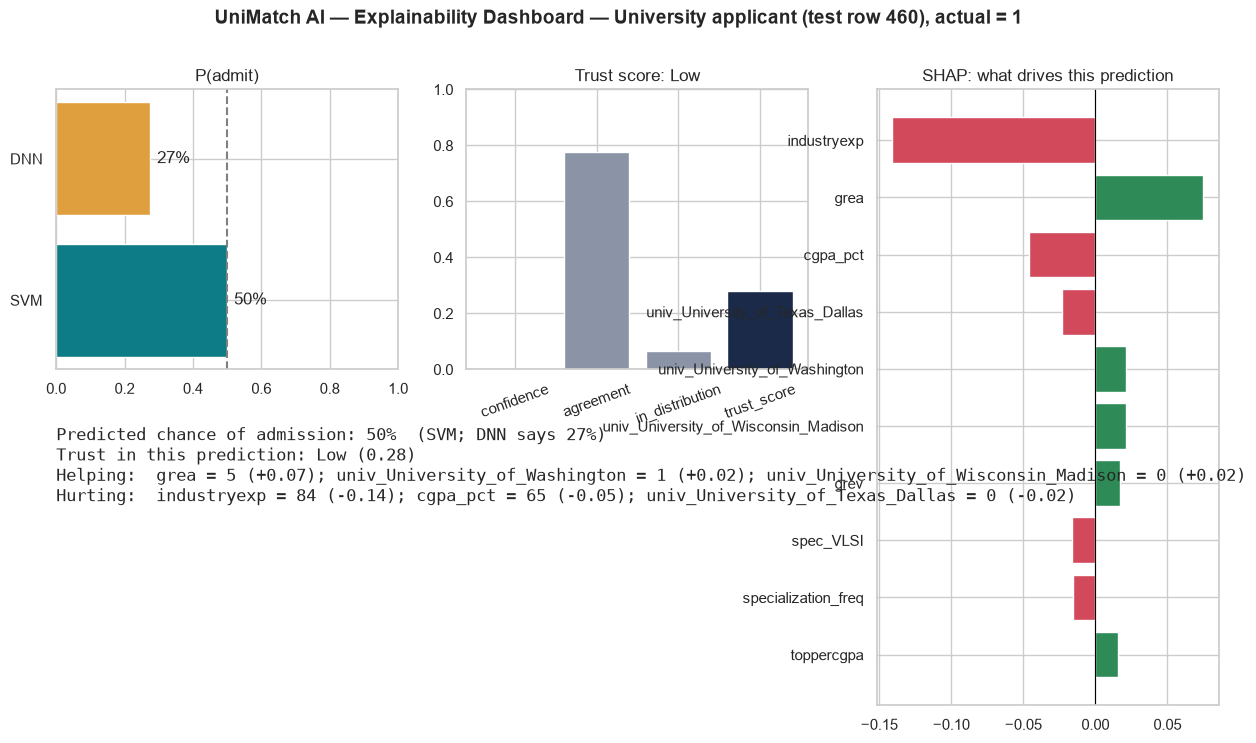

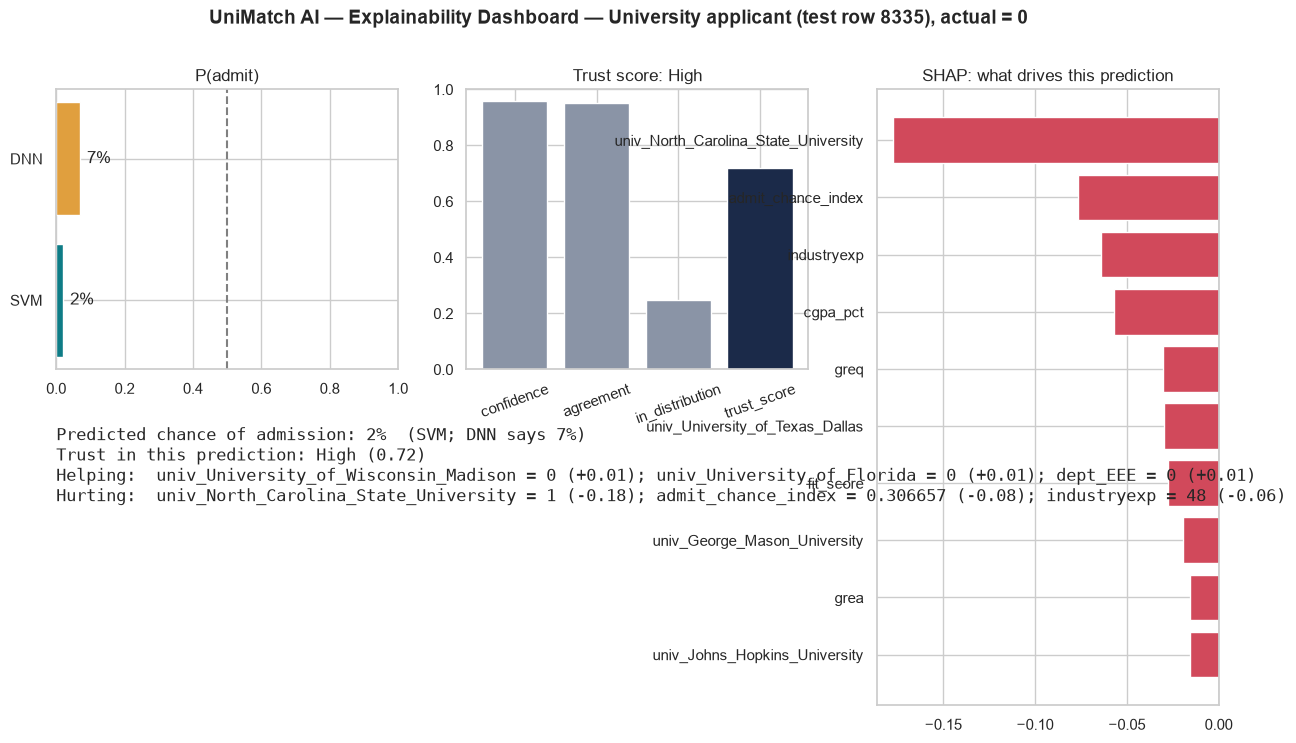

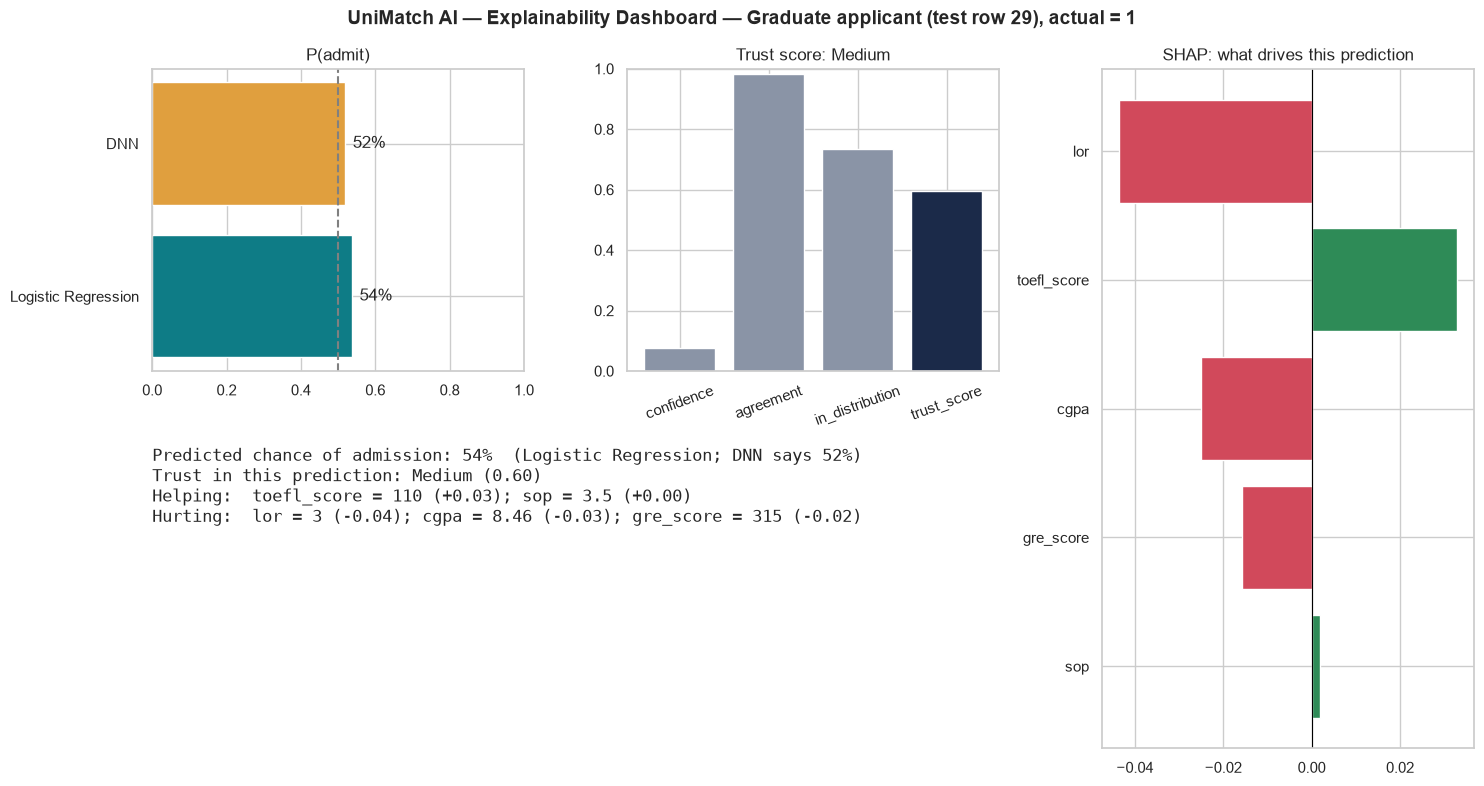

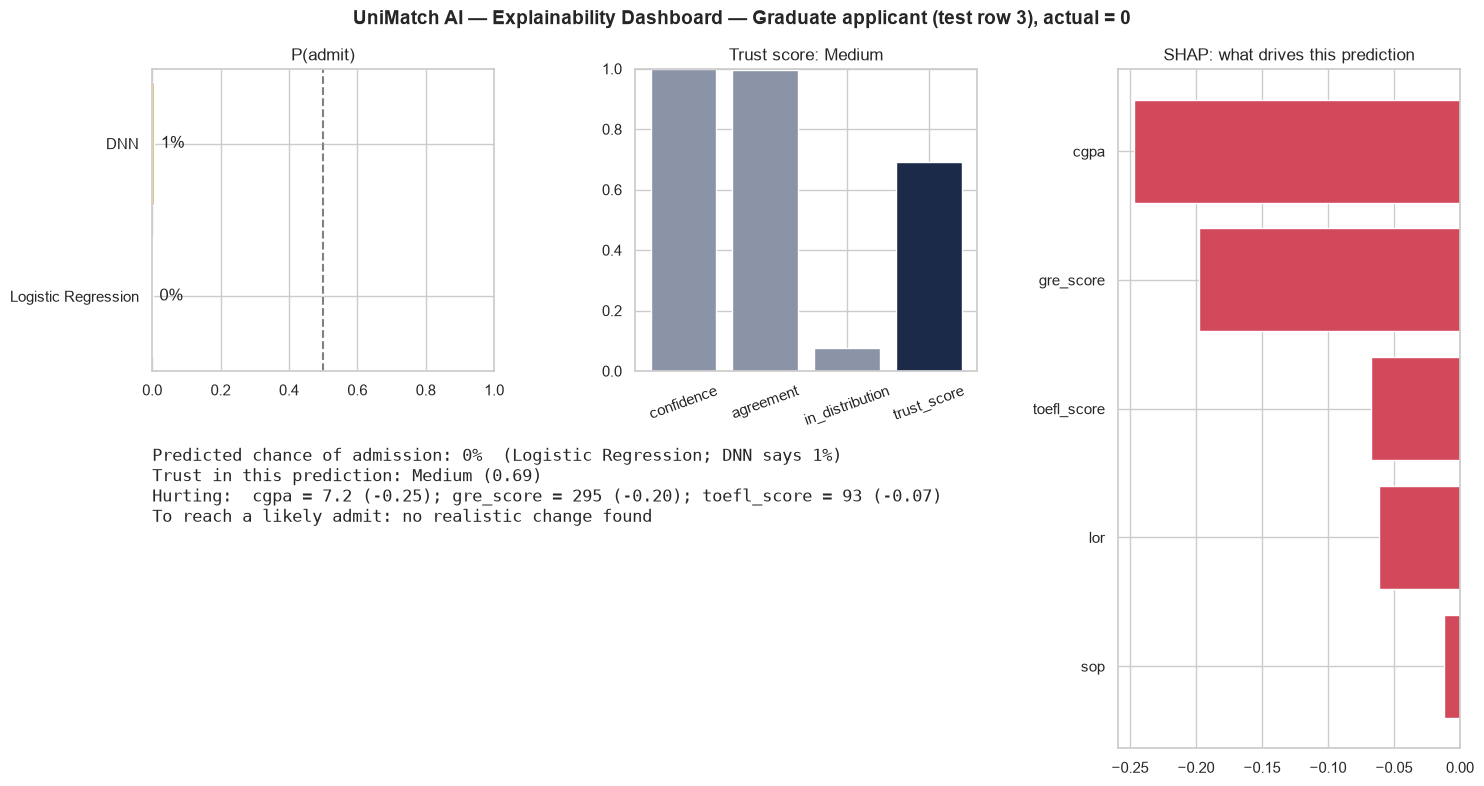

In [15]:
def dashboard(name, i, save=True):
    d = D[name]
    text, contrib = explain_applicant(name, i)
    t = d['trust'].iloc[i]
    fig = plt.figure(figsize=(15, 8))
    gs = fig.add_gridspec(2, 3)
    ax1 = fig.add_subplot(gs[0, 0])
    ax1.barh([d['ml_name'], 'DNN'], [d['p_ml'][i], d['p_dnn'][i]], color=['#0E7C86', '#E09F3E'])
    for k, v in enumerate([d['p_ml'][i], d['p_dnn'][i]]): ax1.text(min(v, 0.85) + 0.02, k, f'{v:.0%}', va='center')
    ax1.axvline(0.5, ls='--', color='grey'); ax1.set_xlim(0, 1); ax1.set_title('P(admit)')
    ax2 = fig.add_subplot(gs[0, 1])
    comps = ['confidence', 'agreement', 'in_distribution', 'trust_score']
    ax2.bar(comps, [t[c] for c in comps], color=['#8A94A6'] * 3 + ['#1B2A49']); ax2.set_ylim(0, 1)
    ax2.set_title(f"Trust score: {t['trust_band']}"); ax2.tick_params(axis='x', rotation=20)
    ax3 = fig.add_subplot(gs[:, 2])
    c = contrib.reindex(contrib.abs().sort_values().index).tail(10)
    ax3.barh(c.index, c.values, color=['#2E8B57' if v > 0 else '#D1495B' for v in c.values])
    ax3.set_title('SHAP: what drives this prediction'); ax3.axvline(0, color='black', lw=0.8)
    ax4 = fig.add_subplot(gs[1, :2]); ax4.axis('off')
    ax4.text(0, 1, text, va='top', fontsize=12, family='monospace', wrap=True)
    fig.suptitle(f'UniMatch AI — Explainability Dashboard — {name.title()} applicant (test row {i}), actual = {d["y_te"][i]}',
                 fontsize=14, weight='bold')
    plt.tight_layout()
    if save: plt.savefig(f'{out_dir}/explainability_dashboard_{name}_row{i}.png', dpi=150)
    plt.show()

for name in D:
    for case in ['borderline', 'confident reject']:
        dashboard(name, D[name]['examples'][case])

In [16]:
# Interactive browsing (works in Colab / Jupyter)
try:
    import ipywidgets as w
    w.interact(lambda dataset, test_row: dashboard(dataset, min(test_row, len(D[dataset]['y_te']) - 1), save=False),
               dataset=list(D), test_row=w.IntSlider(0, 0, 99, 1))
except Exception as e:
    print('ipywidgets not available:', e)

interactive(children=(Dropdown(description='dataset', options=('university', 'graduate'), value='university'),…

## 10. Save the deliverables

In [17]:
summary = f'''# XAI Report — Task 8

## Models explained
{pd.DataFrame([{'dataset': n, 'ML model (Task 6 best, by validation AUC)': d['ml_name'], 'DL model': 'DNN (Task 7)',
                'ML test AUC': round(roc_auc_score(d['y_te'], d['p_ml']), 4),
                'DNN test AUC': round(roc_auc_score(d['y_te'], d['p_dnn']), 4)} for n, d in D.items()]).to_markdown(index=False)}

## SHAP — top features (mean |SHAP|)
{shap_report.groupby(['dataset', 'model']).head(5).round(4).to_markdown(index=False)}

## LIME
Three applicants per dataset (confident admit, borderline, confident reject): `lime_<dataset>_<case>.html`, `lime_<dataset>.png`, `lime_report.csv`.

## Counterfactual analysis (Graduate dataset)
- Applicants predicted "not admitted": {len(counterfactuals)}; a realistic change that flips the prediction was found for {counterfactuals['p_after_ml'].notna().sum()}.
- Most frequently needed improvements: {', '.join(f'{k} ({v})' for k, v in needed.head(4).items())}.

## Trust score
{trust_summary.round(3).to_markdown(index=False)}

## Fairness assessment (proxy groups — no protected attributes in these datasets)
{fairness_summary.round(3).to_markdown(index=False)}

## Notes / limitations
- All explanations are in original feature units; scaling is applied inside the prediction functions.
- SHAP uses a model-agnostic explainer on a sample of test applicants ({N_SHAP['university']} university / {N_SHAP['graduate']} graduate, with {N_BG['university']} / {N_BG['graduate']} background rows); the university sample is small because the selected SVM is slow to evaluate, so its SHAP ranking is indicative.
- University, department and specialization are one-hot columns (`univ_*`, `dept_*`, `spec_*`); a column's SHAP value is the effect of applying to / coming from that particular category.
- Graduate models use the raw applicant attributes (GRE, TOEFL, CGPA, SOP, LOR, research, university rating), so each attribute's SHAP value can be read directly.
- Test rows are the Task 5 test split (by applicant for the University dataset); the explained ML model is the Task 6 model with the best validation ROC-AUC.
- Fairness here uses available applicant groups only; a demographic fairness audit is part of Task 10.
'''
with open(f'{report_dir}/xai_report.md', 'w') as f:
    f.write(summary)
print(summary)

# XAI Report — Task 8

## Models explained
| dataset    | ML model (Task 6 best, by validation AUC)   | DL model     |   ML test AUC |   DNN test AUC |
|:-----------|:--------------------------------------------|:-------------|--------------:|---------------:|
| university | SVM                                         | DNN (Task 7) |        0.7602 |         0.7795 |
| graduate   | Logistic Regression                         | DNN (Task 7) |        0.9558 |         0.9463 |

## SHAP — top features (mean |SHAP|)
| dataset    | model               | feature                              |   mean_abs_shap |
|:-----------|:--------------------|:-------------------------------------|----------------:|
| graduate   | DNN                 | gre_score                            |          0.1194 |
| graduate   | DNN                 | cgpa                                 |          0.0866 |
| graduate   | DNN                 | toefl_score                          |          0.0614 |
| graduate   

In [18]:
# Zip all Task 8 deliverables (Colab only - a local run already writes into the repository's outputs/)
import shutil
try:
    from google.colab import files
    shutil.make_archive('task8_deliverables', 'zip', out_dir)
    files.download('task8_deliverables.zip')
except ModuleNotFoundError:
    print('Not running in Colab - deliverables are in', os.path.abspath(out_dir))


Not running in Colab - deliverables are in /Users/hildamicheal/Desktop/UniMatch-AI/outputs/task8_output


## Task 8 Deliverables Checklist

- [x] **SHAP Report** — `shap_report.csv`, `shap_summary_<dataset>.png`, `shap_waterfall_<dataset>.png`
- [x] **LIME Report** — `lime_report.csv`, `lime_<dataset>.png`, `lime_<dataset>_<case>.html`
- [x] **Counterfactual Analysis** — `counterfactual_analysis.csv`, `counterfactual_summary.png`
- [x] **Explainability Dashboard** — `explainability_dashboard_<dataset>_row<i>.png` (+ interactive widget)
- [x] **Trust Score Report** — `trust_score_report.csv`, `trust_scores.csv`, `trust_score_vs_accuracy.png`
- [x] Feature importance — `feature_importance_permutation.csv/.png`; Fairness — `fairness_report.csv`, `fairness_by_group.csv`
- [x] Summary — `xai_report.md`

**Next step (Task 9):** integrate the models and these explanation functions into the Streamlit application.